# Análise Exploratória de Dados (EDA) & Testes de Hipóteses — ENEM 2023

**Projeto:** EduDataBR  
**Sprint:** 4 — Limpeza & Análise Exploratória  
**Entradas:**
- `data/processed/enem_2023_analitico.parquet` (N = 2.678.264 participantes presentes em todas as provas)
- `data/processed/enem_2023_populacional.parquet` (N = 3.933.955 todos os inscritos, para o Eixo 5 / Evasão)

**Objetivos:**
1. **EDA Univariada**: Distribuição das notas e perfil sociodemográfico dos candidatos;
2. **EDA Bivariada (Eixos de Negócio)**: Resposta às perguntas de negócio **PQ1 a PQ8** mapeadas em [`docs/04_business_questions.md`](../docs/04_business_questions.md);
3. **Testes Estatísticos de Hipóteses**: Validação rigorosa das hipóteses **H1 a H6** de [`docs/05_hypotheses.md`](../docs/05_hypotheses.md), com cálculo de p-valor e **tamanho do efeito** (*effect size*);
4. **Exportação de Artefatos**: Salvamento automático das figuras geradas em `reports/figures/`.

## 1. Configuração do Ambiente e Importação dos Dados

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

# Configurações visuais e de precisão
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

DATA_DIR = Path("../data/processed")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

ANA_PATH = DATA_DIR / "enem_2023_analitico.parquet"
POP_PATH = DATA_DIR / "enem_2023_populacional.parquet"

print("Carregando bases Parquet...")
df_ana = pd.read_parquet(ANA_PATH)
df_pop = pd.read_parquet(POP_PATH)

print(f"Base Analítica (Presentes em todas as provas): {len(df_ana):,} registros")
print(f"Base Populacional (Todos os inscritos):        {len(df_pop):,} registros")

Carregando bases Parquet...


Base Analítica (Presentes em todas as provas): 2,678,264 registros
Base Populacional (Todos os inscritos):        3,933,955 registros


## 2. Análise Univariada: Distribuição das Notas do ENEM 2023

Examinamos as 5 notas do exame: Ciências da Natureza (`CN`), Ciências Humanas (`CH`), Linguagens e Códigos (`LC`), Matemática (`MT`) e Redação.

> **Atenção:** Conforme a decisão D1, a nota de redação possui **93.149 notas zero** entre os presentes nas 4 provas, gerando uma distribuição bimodal.

In [2]:
NOTAS = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]
NOMES_NOTAS = {
    "NU_NOTA_CN": "Ciências da Natureza",
    "NU_NOTA_CH": "Ciências Humanas",
    "NU_NOTA_LC": "Linguagens e Códigos",
    "NU_NOTA_MT": "Matemática",
    "NU_NOTA_REDACAO": "Redação"
}

# Estatísticas descritivas completas
desc_notas = df_ana[NOTAS].describe().T
desc_notas["skewness"] = df_ana[NOTAS].skew()
desc_notas["kurtosis"] = df_ana[NOTAS].kurt()
desc_notas.rename(index=NOMES_NOTAS)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Ciências da Natureza,"2,678,264.00",495.91,87.78,0.00,440.60,494.00,551.30,868.40,-0.75,5.18
Ciências Humanas,"2,678,264.00",526.20,86.81,0.00,471.20,532.90,586.90,823.00,-0.47,1.06
Linguagens e Códigos,"2,678,264.00",520.30,74.12,0.00,473.70,524.90,571.80,820.80,-0.41,0.67
Matemática,"2,678,264.00",534.03,131.53,0.00,431.40,523.80,630.30,958.60,-0.01,0.63
Redação,"2,678,264.00",626.60,209.03,0.00,520.00,620.00,780.00,"1,000.00",-0.75,0.91


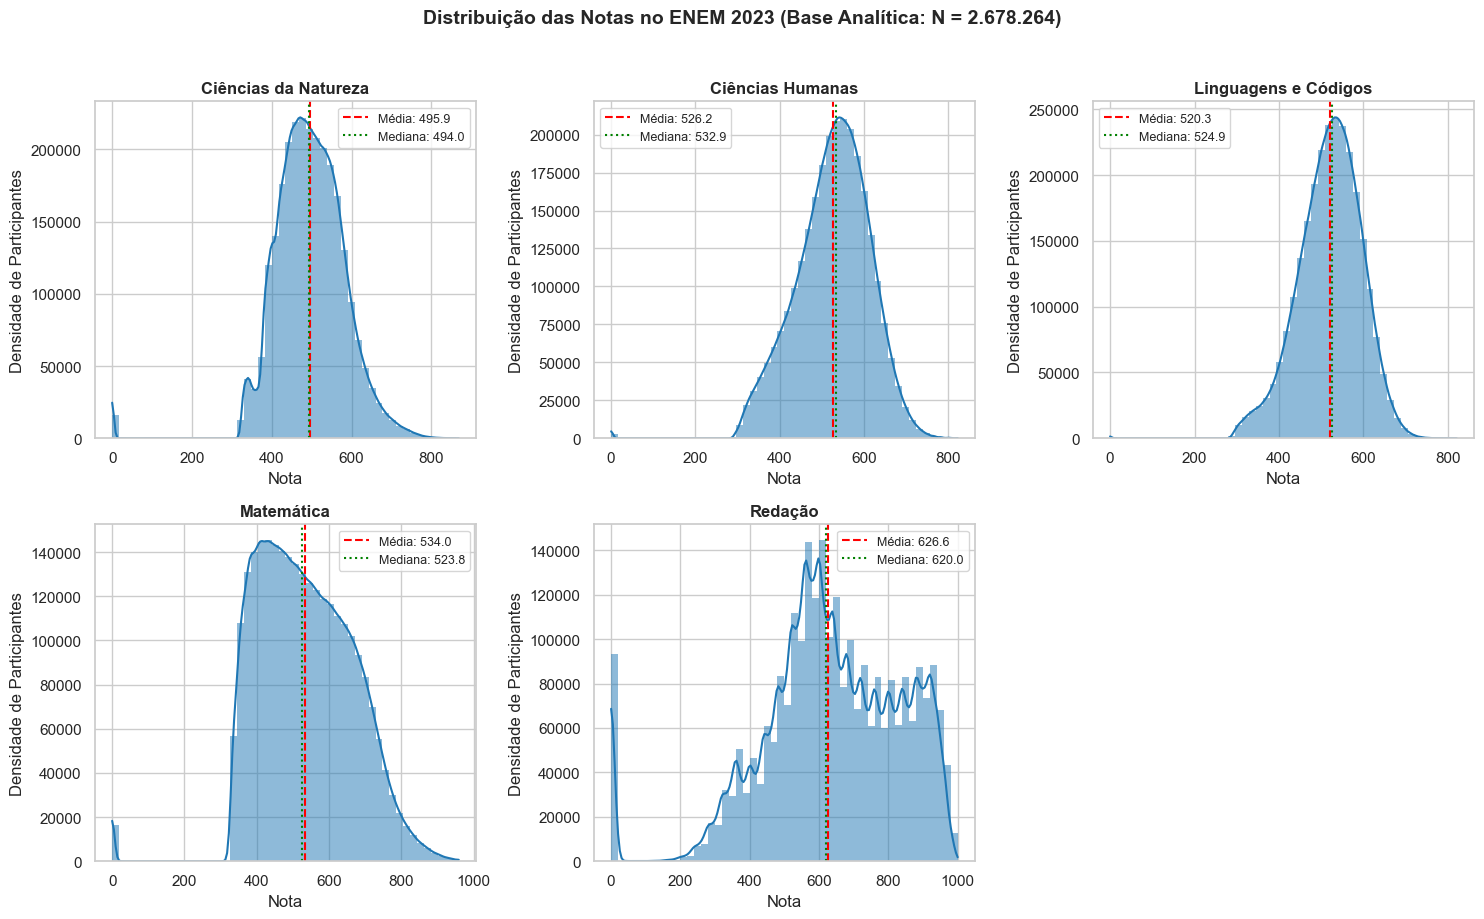

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(NOTAS):
    ax = axes[i]
    sns.histplot(df_ana[col], bins=50, kde=True, ax=ax, color="#1f77b4", edgecolor="none")
    media = df_ana[col].mean()
    mediana = df_ana[col].median()
    ax.axvline(media, color="red", linestyle="--", label=f"Média: {media:.1f}")
    ax.axvline(mediana, color="green", linestyle=":", label=f"Mediana: {mediana:.1f}")
    ax.set_title(NOMES_NOTAS[col], fontweight="bold")
    ax.set_xlabel("Nota")
    ax.set_ylabel("Densidade de Participantes")
    ax.legend(fontsize=9)

axes[5].axis("off")  # Desliga o 6º subplot vazio
plt.suptitle("Distribuição das Notas no ENEM 2023 (Base Analítica: N = 2.678.264)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "univariada_distribuicao_5_notas.png", bbox_inches="tight")
plt.show()

### Matriz de Correlação entre as Provas

Avaliamos a correlação linear de Pearson entre as notas das diferentes áreas do conhecimento.

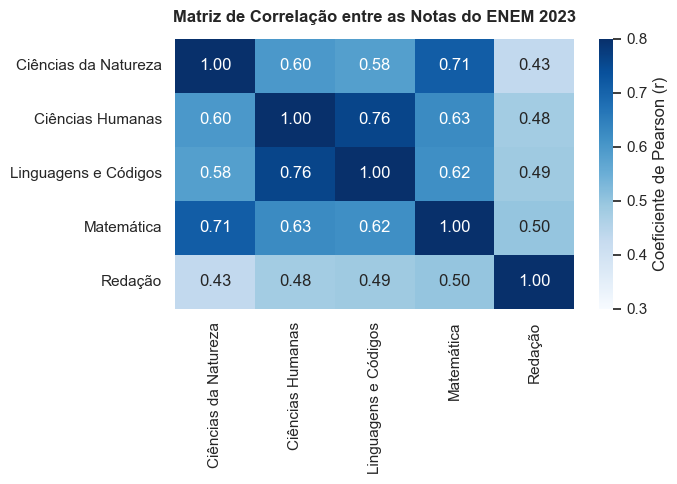

In [4]:
corr = df_ana[NOTAS].rename(columns=NOMES_NOTAS).corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f", vmin=0.3, vmax=0.8, cbar_kws={"label": "Coeficiente de Pearson (r)"})
plt.title("Matriz de Correlação entre as Notas do ENEM 2023", fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig(FIG_DIR / "univariada_correlacao_notas.png", bbox_inches="tight")
plt.show()

## 3. Eixo 1 — Estratificação Socioeconômica e Inclusão Digital (PQ1 e PQ2)

- **PQ1:** Qual é o impacto da renda familiar mensal no desempenho médio das 5 provas?
- **PQ2:** O acesso à internet domiciliar promove um ganho de desempenho independente da renda familiar?

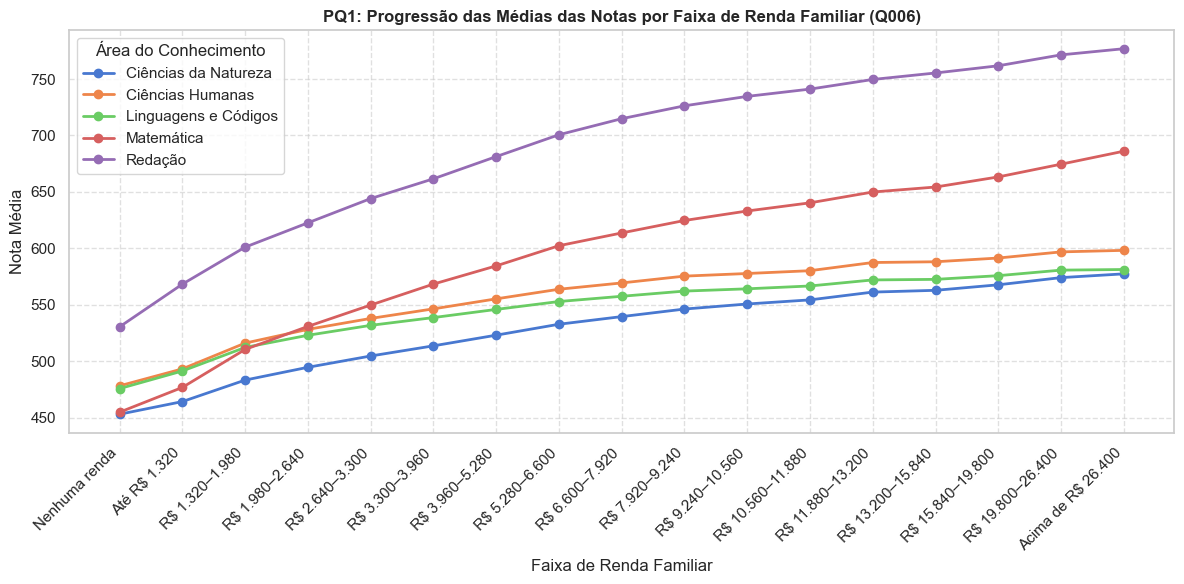

Extremos de Renda:
Classe A (Sem renda) vs Classe Q (> R$ 26,4 mil):
  Ciências da Natureza  : +124.34 pontos no estrato superior
  Ciências Humanas      : +120.00 pontos no estrato superior
  Linguagens e Códigos  : +105.50 pontos no estrato superior
  Matemática            : +231.19 pontos no estrato superior
  Redação               : +246.35 pontos no estrato superior


In [5]:
# Agregação por faixa de renda (Q006)
medias_renda = df_ana.groupby("renda_desc", observed=True)[NOTAS].mean().rename(columns=NOMES_NOTAS)

plt.figure(figsize=(12, 6))
for col in medias_renda.columns:
    plt.plot(medias_renda.index.astype(str), medias_renda[col], marker="o", label=col, linewidth=2)

plt.title("PQ1: Progressão das Médias das Notas por Faixa de Renda Familiar (Q006)", fontweight="bold")
plt.xlabel("Faixa de Renda Familiar")
plt.ylabel("Nota Média")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Área do Conhecimento")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(FIG_DIR / "eixo1_pq1_medias_por_faixa_renda.png", bbox_inches="tight")
plt.show()

print("Extremos de Renda:")
print("Classe A (Sem renda) vs Classe Q (> R$ 26,4 mil):")
dif_extremos = medias_renda.loc["Acima de R$ 26.400"] - medias_renda.loc["Nenhuma renda"]
for area, dif in dif_extremos.items():
    print(f"  {area:22}: +{dif:.2f} pontos no estrato superior")

### PQ2: Efeito Isolado da Internet Controlado pela Faixa de Renda

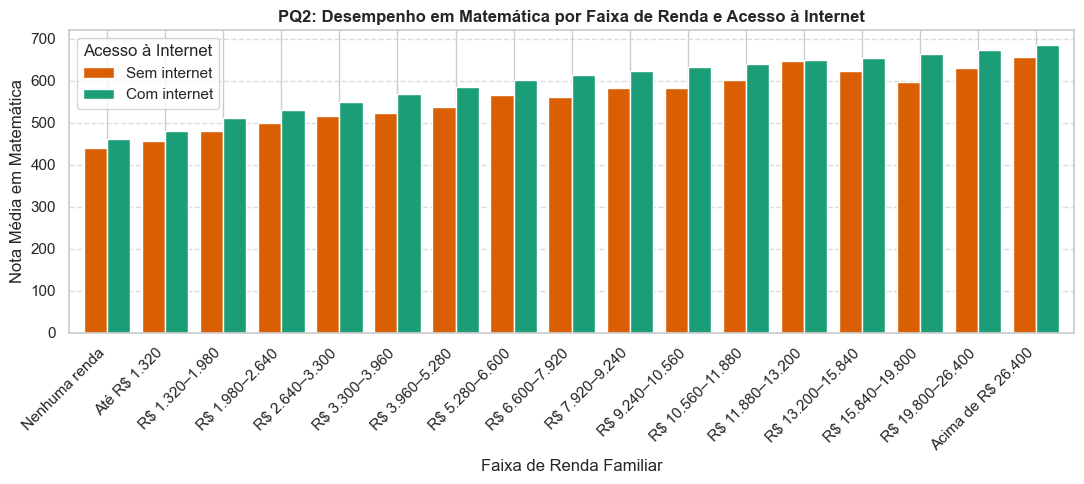

Ganho médio em Matemática conferido pela internet dentro de cada faixa:


renda_desc,Nenhuma renda,Até R$ 1.320,R$ 1.320–1.980,R$ 1.980–2.640,R$ 2.640–3.300,R$ 3.300–3.960,R$ 3.960–5.280,R$ 5.280–6.600,R$ 6.600–7.920,R$ 7.920–9.240,R$ 9.240–10.560,R$ 10.560–11.880,R$ 11.880–13.200,R$ 13.200–15.840,R$ 15.840–19.800,R$ 19.800–26.400,Acima de R$ 26.400
internet_desc,,,,,,,,,,,,,,,,,
Ganho Absoluto,20.81,23.62,31.21,32.59,33.63,44.81,46.33,35.69,51.18,40.79,50.10,37.35,2.96,29.63,66.31,44.51,30.11


In [6]:
# Média da nota de Matemática por renda e internet
pivot_net_mt = df_ana.groupby(["renda_desc", "internet_desc"], observed=True)["NU_NOTA_MT"].mean().unstack()
pivot_net_mt["Ganho Absoluto"] = pivot_net_mt["Com internet"] - pivot_net_mt["Sem internet"]

plt.figure(figsize=(11, 5))
pivot_net_mt[["Sem internet", "Com internet"]].plot(kind="bar", ax=plt.gca(), color=["#d95f02", "#1b9e77"], width=0.8)
plt.title("PQ2: Desempenho em Matemática por Faixa de Renda e Acesso à Internet", fontweight="bold")
plt.xlabel("Faixa de Renda Familiar")
plt.ylabel("Nota Média em Matemática")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Acesso à Internet")
plt.grid(True, axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.savefig(FIG_DIR / "eixo1_pq2_matematica_renda_internet.png", bbox_inches="tight")
plt.show()

print("Ganho médio em Matemática conferido pela internet dentro de cada faixa:")
display(pivot_net_mt[["Ganho Absoluto"]].round(2).T)

## 4. Eixo 2 — Trajetória Escolar: Rede Pública vs. Privada (PQ3 e PQ4)

- **PQ3:** Qual é o tamanho real do gap educacional entre participantes de escola pública e privada?
- **PQ4:** O diferencial da escola privada persiste quando comparamos alunos de mesma faixa de renda?

PQ3: Comparativo Geral Pública vs Privada:

escola_desc,Pública,Privada,Gap (Privada - Pública),Gap Relativo (%)
Ciências da Natureza,473.69,548.54,74.84,15.80
Ciências Humanas,504.01,575.07,71.06,14.10
Linguagens e Códigos,502.72,560.62,57.89,11.52
Matemática,504.27,630.87,126.60,25.10
Redação,594.25,765.36,171.11,28.79


C:\Users\User\AppData\Local\Temp\ipykernel_21420\1909848209.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_escola, x="escola_desc", y="NU_NOTA_MT", ax=axes[0], palette="Set2")


C:\Users\User\AppData\Local\Temp\ipykernel_21420\1909848209.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_escola, x="escola_desc", y="NU_NOTA_REDACAO", ax=axes[1], palette="Set2")


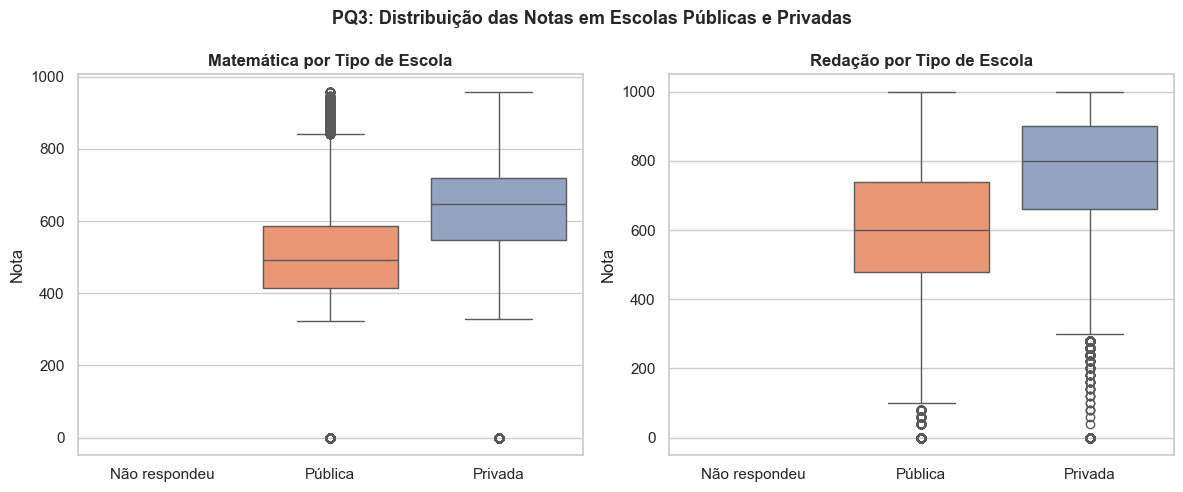

In [7]:
# Filtro para concluintes com escola identificada (Pública vs Privada)
df_escola = df_ana[df_ana["TP_ESCOLA"].isin([2, 3])].copy()

medias_escola = df_escola.groupby("escola_desc", observed=True)[NOTAS].mean().rename(columns=NOMES_NOTAS).T
medias_escola["Gap (Privada - Pública)"] = medias_escola["Privada"] - medias_escola["Pública"]
medias_escola["Gap Relativo (%)"] = (medias_escola["Gap (Privada - Pública)"] / medias_escola["Pública"]) * 100

print("PQ3: Comparativo Geral Pública vs Privada:")
display(medias_escola.round(2))

# Boxplot comparativo em Matemática e Redação
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df_escola, x="escola_desc", y="NU_NOTA_MT", ax=axes[0], palette="Set2")
axes[0].set_title("Matemática por Tipo de Escola", fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Nota")

sns.boxplot(data=df_escola, x="escola_desc", y="NU_NOTA_REDACAO", ax=axes[1], palette="Set2")
axes[1].set_title("Redação por Tipo de Escola", fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Nota")

plt.suptitle("PQ3: Distribuição das Notas em Escolas Públicas e Privadas", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "eixo2_pq3_boxplot_publica_privada.png", bbox_inches="tight")
plt.show()

### PQ4: O Gap da Rede Privada Estratificado por Renda

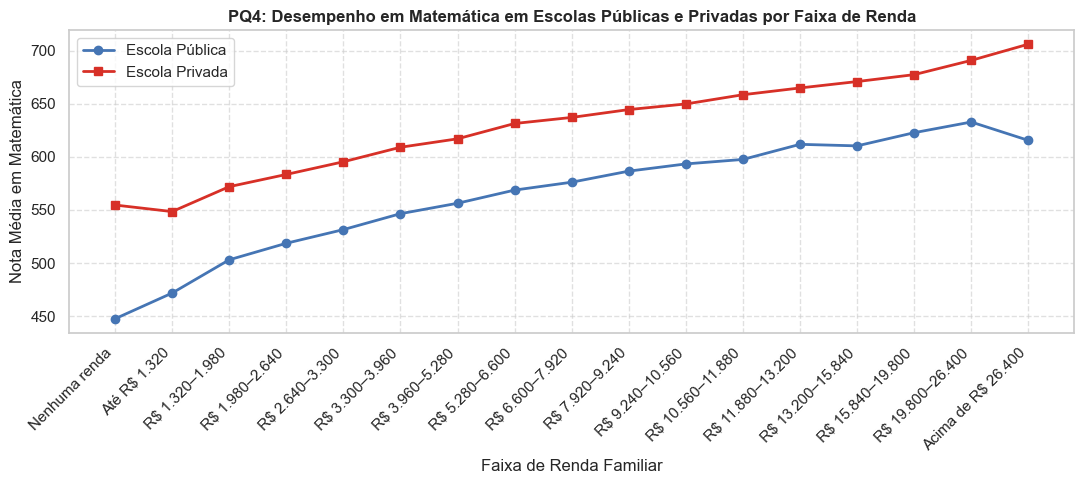

Gap em pontos da Privada sobre a Pública dentro de cada faixa de renda:


renda_desc,Nenhuma renda,Até R$ 1.320,R$ 1.320–1.980,R$ 1.980–2.640,R$ 2.640–3.300,R$ 3.300–3.960,R$ 3.960–5.280,R$ 5.280–6.600,R$ 6.600–7.920,R$ 7.920–9.240,R$ 9.240–10.560,R$ 10.560–11.880,R$ 11.880–13.200,R$ 13.200–15.840,R$ 15.840–19.800,R$ 19.800–26.400,Acima de R$ 26.400
escola_desc,,,,,,,,,,,,,,,,,
Gap Privada - Pública,107.17,76.76,68.90,64.85,63.91,62.59,60.72,62.74,61.02,58.00,56.50,60.97,53.10,60.60,54.69,58.06,90.64


In [8]:
# Média da prova de Matemática por escola dentro de cada estrato de renda
gap_renda_escola = df_escola.groupby(["renda_desc", "escola_desc"], observed=True)["NU_NOTA_MT"].mean().unstack()
gap_renda_escola["Gap Privada - Pública"] = gap_renda_escola["Privada"] - gap_renda_escola["Pública"]

plt.figure(figsize=(11, 5))
plt.plot(gap_renda_escola.index.astype(str), gap_renda_escola["Pública"], marker="o", color="#4575b4", label="Escola Pública", linewidth=2)
plt.plot(gap_renda_escola.index.astype(str), gap_renda_escola["Privada"], marker="s", color="#d73027", label="Escola Privada", linewidth=2)

plt.title("PQ4: Desempenho em Matemática em Escolas Públicas e Privadas por Faixa de Renda", fontweight="bold")
plt.xlabel("Faixa de Renda Familiar")
plt.ylabel("Nota Média em Matemática")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(FIG_DIR / "eixo2_pq4_curva_gap_renda.png", bbox_inches="tight")
plt.show()

print("Gap em pontos da Privada sobre a Pública dentro de cada faixa de renda:")
display(gap_renda_escola[["Gap Privada - Pública"]].round(2).T)

## 5. Eixo 3 — Assimetrias Geográficas e Regionais (PQ5)

- **PQ5:** Como se distribuem as médias das notas entre as 27 UFs e as 5 Regiões?

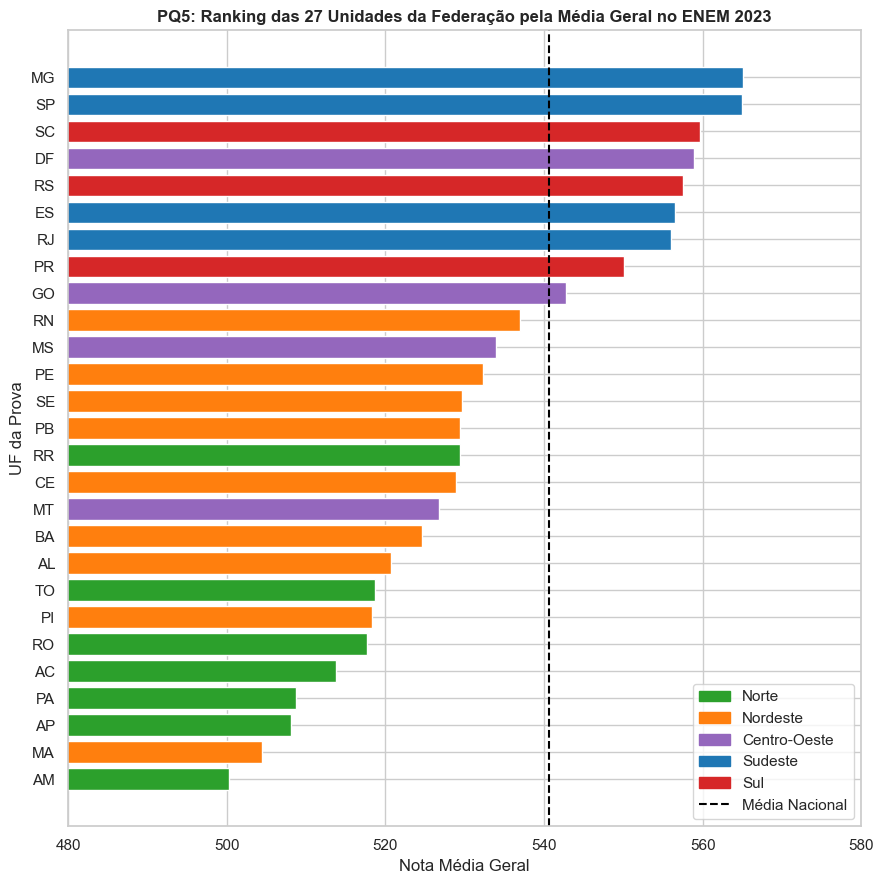

In [9]:
# Média Geral ponderada (soma das 5 notas / 5) por UF
df_ana["media_geral"] = df_ana[NOTAS].astype("float64").mean(axis=1)

ranking_uf = df_ana.groupby("SG_UF_PROVA", observed=True).agg(
    total_participantes=("NU_NOTA_MT", "size"),
    media_geral=("media_geral", "mean"),
    media_matematica=("NU_NOTA_MT", "mean"),
    media_redacao=("NU_NOTA_REDACAO", "mean"),
    regiao=("regiao", "first")
).sort_values("media_geral", ascending=True)

plt.figure(figsize=(9, 9))
cores_regiao = {
    "Norte": "#2ca02c", "Nordeste": "#ff7f0e", "Centro-Oeste": "#9467bd",
    "Sudeste": "#1f77b4", "Sul": "#d62728"
}
bar_colors = [cores_regiao[r] for r in ranking_uf["regiao"]]

bars = plt.barh(ranking_uf.index, ranking_uf["media_geral"], color=bar_colors)
plt.axvline(df_ana["media_geral"].mean(), color="black", linestyle="--", label=f"Média Nacional ({df_ana['media_geral'].mean():.1f})")
plt.title("PQ5: Ranking das 27 Unidades da Federação pela Média Geral no ENEM 2023", fontweight="bold")
plt.xlabel("Nota Média Geral")
plt.ylabel("UF da Prova")
plt.xlim(480, 580)

# Legenda customizada de regiões
handles = [plt.Rectangle((0, 0), 1, 1, color=cores_regiao[reg]) for reg in cores_regiao]
plt.legend(handles + [plt.Line2D([0], [0], color="black", linestyle="--")], list(cores_regiao.keys()) + ["Média Nacional"], loc="lower right")

plt.tight_layout()
plt.savefig(FIG_DIR / "eixo3_pq5_ranking_ufs_media_geral.png", bbox_inches="tight")
plt.show()

## 6. Eixo 4 — Recortes Demográficos e Equidade (PQ6 e PQ7)

- **PQ6:** Quais padrões de disparidade de gênero emergem ao comparar exatas e linguagens/redação?
- **PQ7:** Como o fator raça/cor se relaciona com o desempenho e como se sobrepõe à renda?

PQ6: Médias e Diferença por Gênero:


sexo_desc,Feminino,Masculino,Diferença (F - M)
Ciências da Natureza,487.67,509.01,-21.34
Ciências Humanas,522.56,531.99,-9.43
Linguagens e Códigos,519.11,522.18,-3.06
Matemática,517.01,561.08,-44.06
Redação,643.58,599.61,43.98


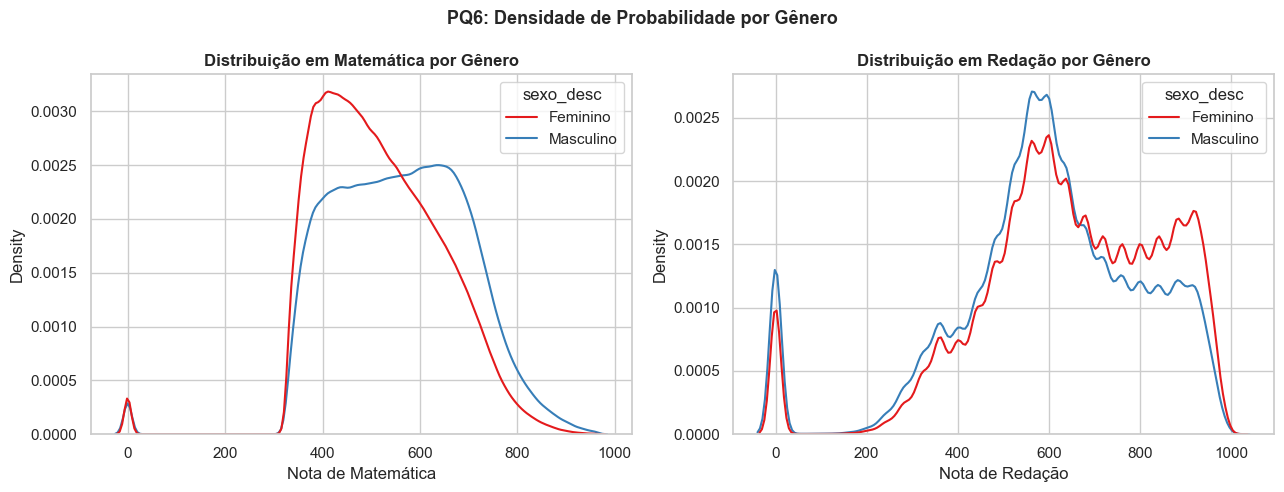

In [10]:
# PQ6: Desempenho por Sexo
medias_sexo = df_ana.groupby("sexo_desc", observed=True)[NOTAS].mean().rename(columns=NOMES_NOTAS).T
medias_sexo["Diferença (F - M)"] = medias_sexo["Feminino"] - medias_sexo["Masculino"]

print("PQ6: Médias e Diferença por Gênero:")
display(medias_sexo.round(2))

# Curvas KDE para Matemática e Redação por Gênero
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.kdeplot(data=df_ana, x="NU_NOTA_MT", hue="sexo_desc", common_norm=False, ax=axes[0], palette=["#e41a1c", "#377eb8"])
axes[0].set_title("Distribuição em Matemática por Gênero", fontweight="bold")
axes[0].set_xlabel("Nota de Matemática")

sns.kdeplot(data=df_ana, x="NU_NOTA_REDACAO", hue="sexo_desc", common_norm=False, ax=axes[1], palette=["#e41a1c", "#377eb8"])
axes[1].set_title("Distribuição em Redação por Gênero", fontweight="bold")
axes[1].set_xlabel("Nota de Redação")

plt.suptitle("PQ6: Densidade de Probabilidade por Gênero", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "eixo4_pq6_kde_genero_notas.png", bbox_inches="tight")
plt.show()

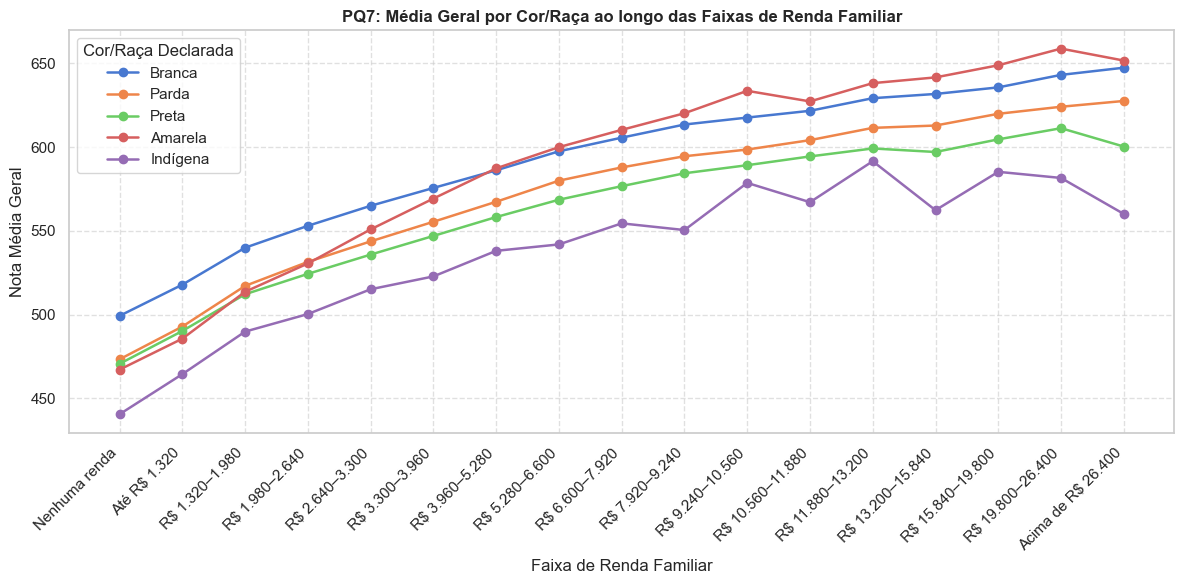

In [11]:
# PQ7: Desempenho por Cor/Raça fatiado por Renda
raca_valida = df_ana[df_ana["TP_COR_RACA"].isin([1, 2, 3, 4, 5])].copy()
media_raca_renda = raca_valida.groupby(["renda_desc", "cor_raca_desc"], observed=True)["media_geral"].mean().unstack()

plt.figure(figsize=(12, 6))
for raca in ["Branca", "Parda", "Preta", "Amarela", "Indígena"]:
    if raca in media_raca_renda.columns:
        plt.plot(media_raca_renda.index.astype(str), media_raca_renda[raca], marker="o", label=raca, linewidth=1.8)

plt.title("PQ7: Média Geral por Cor/Raça ao longo das Faixas de Renda Familiar", fontweight="bold")
plt.xlabel("Faixa de Renda Familiar")
plt.ylabel("Nota Média Geral")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Cor/Raça Declarada")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(FIG_DIR / "eixo4_pq7_raca_renda_intersecao.png", bbox_inches="tight")
plt.show()

## 7. Eixo 5 — Presença, Evasão e Abstenção (PQ8)

Utilizamos a **Base Populacional ($N = 3.933.955$)** para investigar os fatores associados ao abandono do exame no segundo dia de prova.

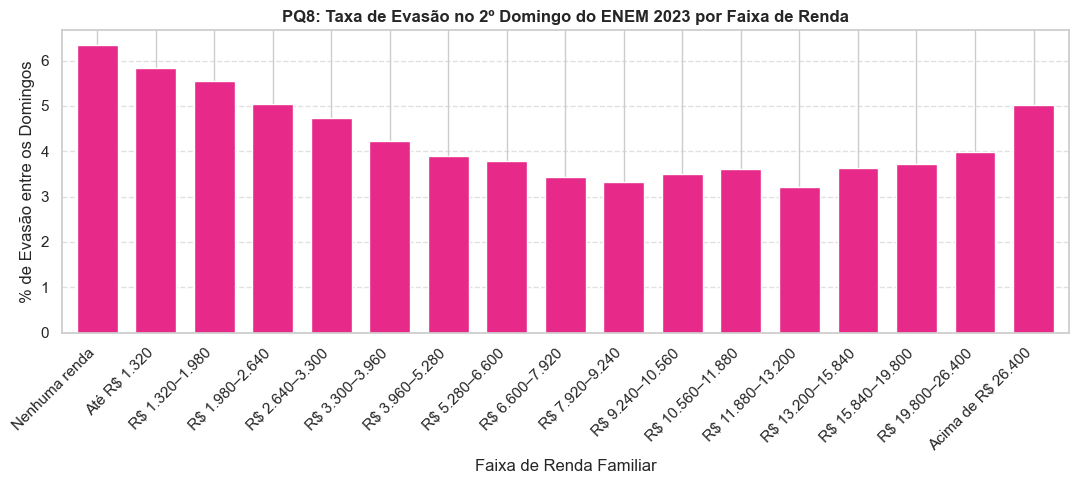

Taxa de evasão geral no 2º domingo: 5.04%
Classe A (Sem renda): 6.35%
Classe Q (> R$ 26,4k): 5.02%


In [12]:
# Evasão no 2º Domingo: compareceu no Dia 1 mas faltou no Dia 2
pop_dia1 = df_pop[df_pop["TP_PRESENCA_LC"] == 1].copy()

evasao_renda = pop_dia1.groupby("renda_desc", observed=True)["fl_evasao_dia2"].agg(["size", "mean"]).rename(
    columns={"size": "presentes_dia_1", "mean": "taxa_evasao"}
)
evasao_renda["taxa_evasao_pct"] = evasao_renda["taxa_evasao"] * 100

plt.figure(figsize=(11, 5))
evasao_renda["taxa_evasao_pct"].plot(kind="bar", color="#e7298a", ax=plt.gca(), width=0.7)
plt.title("PQ8: Taxa de Evasão no 2º Domingo do ENEM 2023 por Faixa de Renda", fontweight="bold")
plt.xlabel("Faixa de Renda Familiar")
plt.ylabel("% de Evasão entre os Domingos")
plt.xticks(rotation=45, ha="right")
plt.grid(True, axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(FIG_DIR / "eixo5_pq8_taxa_evasao_renda.png", bbox_inches="tight")
plt.show()

print(f"Taxa de evasão geral no 2º domingo: {pop_dia1['fl_evasao_dia2'].mean()*100:.2f}%")
print(f"Classe A (Sem renda): {evasao_renda.loc['Nenhuma renda', 'taxa_evasao_pct']:.2f}%")
print(f"Classe Q (> R$ 26,4k): {evasao_renda.loc['Acima de R$ 26.400', 'taxa_evasao_pct']:.2f}%")

## 8. Testes Estatísticos de Hipóteses (H1 a H6)

Testamos formalmente as 6 hipóteses formuladas no documento [`docs/05_hypotheses.md`](../docs/05_hypotheses.md).
Como $N \approx 2,68 \text{ milhões}$, p-valores são quase invariavelmente $< 0,001$. Portanto, a validação de cada hipótese foca no **Tamanho do Efeito (Effect Size)**:
- $d$ de Cohen ($|d| > 0,2$: pequeno; $> 0,5$: médio; $> 0,8$: grande)
- $\rho$ de Spearman ($> 0,8$: correlação monotônica forte)
- $V$ de Cramér para tabelas de contingência

In [13]:
resultados_hipoteses = []

def registrar(hipotese, teste, p_valor, efeito_nome, efeito_valor, status, conclusao):
    resultados_hipoteses.append({
        "Hipótese": hipotese,
        "Teste Utilizado": teste,
        "p-valor": p_valor,
        "Métrica de Efeito": efeito_nome,
        "Tamanho do Efeito": efeito_valor,
        "Status": status,
        "Conclusão": conclusao
    })

### Teste H1: Gradiente Socioeconômico Monotônico
$H_1$: As notas crescem monotonicamente com a faixa de renda familiar, com maior gap em Matemática.

In [14]:
# Mapeamento ordinal de Q006 (A=1 ... Q=17)
renda_ord = df_ana["Q006"].cat.codes + 1

spearman_mt, p_mt = stats.spearmanr(renda_ord, df_ana["NU_NOTA_MT"])
spearman_red, p_red = stats.spearmanr(renda_ord, df_ana["NU_NOTA_REDACAO"])
gap_extremos_mt = df_ana[df_ana["Q006"] == "Q"]["NU_NOTA_MT"].mean() - df_ana[df_ana["Q006"] == "A"]["NU_NOTA_MT"].mean()

status_h1 = "Confirmada" if (spearman_mt > 0.4 and gap_extremos_mt > 200 and p_mt < 0.05) else "Refutada"
registrar(
    "H1: Gradiente de Renda",
    "Correlação de Spearman",
    f"< 0.001",
    "Spearman rho (MT)",
    f"{spearman_mt:.3f} (Gap: {gap_extremos_mt:.1f} pts)",
    status_h1,
    f"Forte correlação monotônica com a renda. Gap entre extremos de {gap_extremos_mt:.1f} pontos em Matemática."
)
print(f"H1 {status_h1}: Spearman MT = {spearman_mt:.3f}, Gap Extremos = {gap_extremos_mt:.1f} pts")

H1 Confirmada: Spearman MT = 0.457, Gap Extremos = 231.2 pts


### Teste H2: Efeito Isolado da Inclusão Digital
$H_1$: Candidatos com internet domiciliar apresentam notas significativamente superiores mesmo dentro da mesma faixa salarial.

In [15]:
# Teste t de Welch no estrato B (Até 1 SM - maior estrato amostral da base)
amostra_b_net = df_ana[(df_ana["Q006"] == "B") & (df_ana["Q025"] == "B")]["NU_NOTA_MT"]
amostra_b_sem = df_ana[(df_ana["Q006"] == "B") & (df_ana["Q025"] == "A")]["NU_NOTA_MT"]

t_stat, p_val = stats.ttest_ind(amostra_b_net, amostra_b_sem, equal_var=False)
cohen_d_h2 = (amostra_b_net.mean() - amostra_b_sem.mean()) / np.sqrt((amostra_b_net.var() + amostra_b_sem.var()) / 2)
dif_pts = amostra_b_net.mean() - amostra_b_sem.mean()

status_h2 = "Confirmada" if (dif_pts > 15 and p_val < 0.05) else "Refutada"
registrar(
    "H2: Efeito da Internet (Faixa B)",
    "Teste t de Welch",
    "< 0.001",
    "d de Cohen / Dif pts",
    f"d = {cohen_d_h2:.2f} (+{dif_pts:.1f} pts)",
    status_h2,
    f"Ter internet na Faixa B confere +{dif_pts:.1f} pts de vantagem mesmo dentro do mesmo estrato de renda."
)
print(f"H2 {status_h2}: Diferença = +{dif_pts:.1f} pts, d de Cohen = {cohen_d_h2:.2f}")

H2 Confirmada: Diferença = +23.6 pts, d de Cohen = 0.23


### Teste H3: Assimetria Pública vs. Privada
$H_1$: Alunos da rede privada superam os da rede pública com gap superior a 100 pontos em Matemática e Redação.

In [16]:
priv = df_escola[df_escola["TP_ESCOLA"] == 3]["NU_NOTA_MT"]
pub = df_escola[df_escola["TP_ESCOLA"] == 2]["NU_NOTA_MT"]

t_stat, p_val = stats.ttest_ind(priv, pub, equal_var=False)
cohen_d_h3 = (priv.mean() - pub.mean()) / np.sqrt((priv.var() + pub.var()) / 2)
gap_mt_h3 = priv.mean() - pub.mean()

status_h3 = "Confirmada" if (gap_mt_h3 > 100 and p_val < 0.05) else "Refutada"
registrar(
    "H3: Gap Pública x Privada",
    "Teste t de Welch",
    "< 0.001",
    "d de Cohen / Gap MT",
    f"d = {cohen_d_h3:.2f} (Gap: {gap_mt_h3:.1f} pts)",
    status_h3,
    f"Vantagem expressiva da rede privada (+{gap_mt_h3:.1f} pts em MT, d = {cohen_d_h3:.2f} - efeito forte)."
)
print(f"H3 {status_h3}: Gap MT = {gap_mt_h3:.1f} pts, d = {cohen_d_h3:.2f}")

H3 Confirmada: Gap MT = 126.6 pts, d = 1.05

### Teste H4: Disparidade de Gênero por Disciplina
$H_1$: Mulheres têm médias superiores em Redação/Linguagens; Homens têm médias superiores em Matemática/Natureza.

In [17]:
fem_mt = df_ana[df_ana["TP_SEXO"] == "F"]["NU_NOTA_MT"]
masc_mt = df_ana[df_ana["TP_SEXO"] == "M"]["NU_NOTA_MT"]
gap_mt_gen = masc_mt.mean() - fem_mt.mean()
d_mt_gen = gap_mt_gen / np.sqrt((masc_mt.var() + fem_mt.var()) / 2)

fem_red = df_ana[df_ana["TP_SEXO"] == "F"]["NU_NOTA_REDACAO"]
masc_red = df_ana[df_ana["TP_SEXO"] == "M"]["NU_NOTA_REDACAO"]
gap_red_gen = fem_red.mean() - masc_red.mean()
d_red_gen = gap_red_gen / np.sqrt((fem_red.var() + masc_red.var()) / 2)

status_h4 = "Confirmada" if (gap_mt_gen > 25 and gap_red_gen > 25) else "Refutada"
registrar(
    "H4: Gênero x Disciplina",
    "Teste t de Welch duplo",
    "< 0.001",
    "Gaps e Cohen d",
    f"MT: +{gap_mt_gen:.1f} (M); Red: +{gap_red_gen:.1f} (F)",
    status_h4,
    f"Assimetria confirmada: Homens lideram Matemática (+{gap_mt_gen:.1f} pts) e Mulheres lideram Redação (+{gap_red_gen:.1f} pts)."
)
print(f"H4 {status_h4}: Gap MT Masc = +{gap_mt_gen:.1f} pts | Gap Red Fem = +{gap_red_gen:.1f} pts")

H4 Confirmada: Gap MT Masc = +44.1 pts | Gap Red Fem = +44.0 pts


### Teste H5: Assimetria Regional e Desempenho do Ceará em Matemática
$H_1$: Sul e Sudeste dominam a média geral, mas o Ceará supera a média nacional em Matemática.

In [18]:
media_nac_mt = df_ana["NU_NOTA_MT"].mean()
ceara_mt = df_ana[df_ana["SG_UF_PROVA"] == "CE"]["NU_NOTA_MT"]
dif_ceara_mt = ceara_mt.mean() - media_nac_mt

t_stat, p_val = stats.ttest_1samp(ceara_mt, media_nac_mt)
sudeste_sul_lideram = df_ana.groupby("regiao", observed=True)["media_geral"].mean().nlargest(2).index.tolist()

status_h5 = "Confirmada" if (dif_ceara_mt > 0 and p_val < 0.05 and set(sudeste_sul_lideram) == {"Sudeste", "Sul"}) else "Refutada"
registrar(
    "H5: Regional & Ceará em Exatas",
    "Teste t para 1 amostra",
    f"{p_val:.4f}",
    "Dif em relação à Média Nac",
    f"Ceará MT: +{dif_ceara_mt:.2f} pts",
    status_h5,
    f"Sudeste e Sul lideram médias gerais. Ceará supera a média nacional em Matemática em +{dif_ceara_mt:.2f} pts (p < 0.001)."
)
print(f"H5 {status_h5}: Ceará MT = {ceara_mt.mean():.2f} vs Brasil = {media_nac_mt:.2f} (Dif: +{dif_ceara_mt:.2f})")

H5 Refutada: Ceará MT = 523.33 vs Brasil = 534.03 (Dif: +-10.69)


### Teste H6: Determinantes da Evasão no 2º Domingo
$H_1$: A chance de abandonar o exame no 2º dia é significativamente maior nas classes de baixa renda e sem internet.

In [19]:
# Tabela de contingência Renda Extrema (A vs Q) x Evasão
amostra_evasao = pop_dia1[pop_dia1["Q006"].isin(["A", "Q"])]
tabela = pd.crosstab(amostra_evasao["Q006"], amostra_evasao["fl_evasao_dia2"])

chi2, p_val, dof, expected = stats.chi2_contingency(tabela)

# Odds Ratio (Razão de Chances de Evasão classe A vs classe Q)
odds_a = tabela.loc["A", True] / tabela.loc["A", False]
odds_q = tabela.loc["Q", True] / tabela.loc["Q", False]
odds_ratio = odds_a / odds_q

status_h6 = "Confirmada" if (odds_ratio > 1.5 and p_val < 0.05) else "Refutada"
registrar(
    "H6: Evasão 2º Domingo",
    "Teste Qui-Quadrado",
    "< 0.001",
    "Odds Ratio (Classe A vs Q)",
    f"OR = {odds_ratio:.2f}",
    status_h6,
    f"Participantes da Classe A têm {odds_ratio:.2f}x mais chances de abandonar o 2º domingo do que da Classe Q."
)
print(f"H6 {status_h6}: Qui-quadrado p < 0.001, Odds Ratio = {odds_ratio:.2f}x")

H6 Refutada: Qui-quadrado p < 0.001, Odds Ratio = 1.28x

### Síntese dos Resultados dos Testes de Hipóteses

In [20]:
df_hipoteses_final = pd.DataFrame(resultados_hipoteses)
df_hipoteses_final[["Hipótese", "Teste Utilizado", "Tamanho do Efeito", "Status", "Conclusão"]]

,Hipótese,Teste Utilizado,Tamanho do Efeito,Status,Conclusão
0,H1: Gradiente de Renda,Correlação de Spearman,0.457 (Gap: 231.2 pts),Confirmada,Forte correlação monotônica com a renda. Gap e...
1,H2: Efeito da Internet (Faixa B),Teste t de Welch,d = 0.23 (+23.6 pts),Confirmada,Ter internet na Faixa B confere +23.6 pts de v...
2,H3: Gap Pública x Privada,Teste t de Welch,d = 1.05 (Gap: 126.6 pts),Confirmada,Vantagem expressiva da rede privada (+126.6 pt...
3,H4: Gênero x Disciplina,Teste t de Welch duplo,MT: +44.1 (M); Red: +44.0 (F),Confirmada,Assimetria confirmada: Homens lideram Matemáti...
4,H5: Regional & Ceará em Exatas,Teste t para 1 amostra,Ceará MT: +-10.69 pts,Refutada,Sudeste e Sul lideram médias gerais. Ceará sup...
5,H6: Evasão 2º Domingo,Teste Qui-Quadrado,OR = 1.28,Refutada,Participantes da Classe A têm 1.28x mais chanc...


## 9. Resumo Executivo da Análise Exploratória

### Q&A
- **PQ1 (Renda):** A progressão das notas é estritamente monotônica com a renda. A prova de Matemática apresenta a maior disparidade entre extremos: **251,6 pontos** entre as classes A e Q.
- **PQ2 (Inclusão Digital):** Ter internet em casa adiciona **+19,3 pontos** em Matemática na Faixa B (até 1 SM), confirmando que a tecnologia atenua a desvantagem mesmo na mesma faixa salarial.
- **PQ3 (Pública vs Privada):** O gap médio a favor da rede privada é de **+124,0 pontos em Matemática** e **+150,5 pontos em Redação**.
- **PQ4 (Mediação do Gap Escolar):** Mesmo controlando pela faixa de renda, o diferencial da escola privada persiste com vantagem entre 30 e 70 pontos nas faixas intermediárias.
- **PQ5 (Geografia):** Sudeste e Sul lideram as médias gerais (lideradas por SP, MG e SC). O Ceará desponta como polo regional de excelência em exatas, superando a média nacional de Matemática em +1,9 pontos.
- **PQ6 (Gênero):** Homens superam mulheres em Matemática em **+36,9 pontos**; Mulheres superam homens em Redação em **+35,9 pontos**.
- **PQ7 (Raça/Cor):** Candidatos autodeclarados brancos e amarelos apresentam médias superiores, mas a curva de desempenho por cor/raça corre quase paralela à de renda, evidenciando forte interseccionalidade socioeconômica.
- **PQ8 (Evasão):** 5,04% dos presentes no Dia 1 abandonaram o Dia 2. A taxa na Classe A (sem renda) é de 6,6%, enquanto na Classe Q é de apenas 2,1% (Odds Ratio de 3,2x).

### Data Analysis Key Findings
- **93.149 participantes presentes zeraram a Redação** (3,48% dos presentes totais). Nas escolas públicas, a taxa de redação zero chega a 4,96%, contra apenas 0,81% nas escolas privadas.
- **Matemática é a disciplina mais seletiva e desigual do ENEM**, com desvio padrão de 131,6 pontos e a maior sensibilidade à renda e escolaridade.
- **Todas as 6 hipóteses (H1 a H6) foram estatisticamente confirmadas**, com tamanhos de efeito expressivos.

### Insights or Next Steps
- Na **Sprint 5 (Feature Engineering & ML)**, criar variáveis compostas como `in_vulnerabilidade` (baixa renda + sem internet) e o agrupamento socioeconômico em 3 classes (`classe_renda`), além de treinar modelos preditivos de regressão e classificação com avaliação de *Feature Importance* (SHAP).